# Recreating *Aspect-based Sentiment Analysis on Hotel Reviews*


This notebook recreates the experimental **workflow** of [Yu (2016)](https://cs229.stanford.edu/proj2016spr/report/032.pdf): predict 1–5 star and three-way polarity labels from hotel-review text, compare balancing strategies and algorithms, test bag-of-words features, and compare overall with aspect-specific training. It runs on the included **1,000-review public substitute sample**. Its numerical results are new measurements on that sample, not a replication of the paper's reported accuracy.

**Included saved run:** the majority-class baseline is 46.0%; the class-weighted SVM scores 57.2% overall star accuracy on its test split; aspect-specific training improves star accuracy on 2 of the 5 available aspects. These findings apply only to the substitute sample. If you change the data, rerun and use the recalculated outputs below.

Run all cells from top to bottom. The included CSV sits beside this notebook. To use a larger compatible CSV, change `DATA_PATH` below. Select the project-local `.venv-paper` Python environment if your notebook editor asks for a kernel; the required packages are `pandas`, `numpy`, `scikit-learn`, `matplotlib`, and `ipykernel`.

## Context & Methods

**Paper and data.** Yu used 235,793 TripAdvisor reviews from Wang et al., combining review title and body. The paper reports overall rating and seven aspect ratings. The original corpus and exact random splits were not supplied here. The included substitute is a 1,000-row English sample from [Niimi's processed TripAdvisor dataset](https://github.com/jniimi/tripadvisor_dataset), derived from a different [Li et al. hotel review collection](https://aclanthology.org/D13-1199/). This substitute covers 2012 and provides five aspect labels: cleanliness, value, location, rooms, and sleep quality. It does not provide service or business-service labels. These differences prevent an exact reproduction of Figures 1–4 or Table 1.

**Paper settings implemented.** A random two-thirds/one-third train/test split; 1–5 star classification via Multinomial Naive Bayes and linear SVM; linear regression for continuous stars; no balance, inverse-frequency class weights, random oversampling, and random undersampling; word unigrams with stop-word removal, character 5-grams with document-frequency limits, and word 2/3-grams with document-frequency limits, with and without TF-IDF.

### Key assumptions

| Item | Reproduction choice |
|---|---|
| Random state | 42, since the paper gives none. |
| SVM | `LinearSVC(C=1, max_iter=5000)`; the paper does not report hyperparameters. |
| Baseline for balance and algorithm comparisons | Word unigrams + TF-IDF; the paper does not specify the exact baseline configuration used in those figures. |
| Accuracy | Correct predictions / test examples. The paper's prose says mismatches / test examples, which defines *error rate*; its tables/figures call the values accuracy. |
| Regression star score | Fraction of predictions within 0.5 star of the true rating, as stated in the paper. |
| Regression polarity | Round clipped predictions to 1–5 before mapping to negative (1–2), neutral (3), or positive (4–5); the paper does not specify how continuous predictions become three groups. |
| Missing aspect scores | Omit only the missing labels for that aspect; all vectorizers and resampling fit on training rows only. |
| Holdout | Random review-level split as in the paper; reviews from the same hotel may appear in both partitions. |

The paper's original subset sizes are 10,673, 30,050, 45,970, and 94,926. The sample-size comparison below uses smaller sizes appropriate to the public substitute.

## Data

### 1. Imports and settings

In [1]:
import os
from pathlib import Path
import warnings

os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mplconfig'))
Path(os.environ['MPLCONFIGDIR']).mkdir(exist_ok=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED = 42
DATA_PATH = Path('tripadvisor_sample_1000.csv')
PAPER_SIZES = [10673, 30050, 45970, 94926]
ASPECT_CANDIDATES = ['service', 'rooms', 'location', 'value', 'cleanliness',
                     'sleep_quality', 'business_service', 'check_in']
BLUE, GOLD, PINK, CHARCOAL = '#275D8C', '#C58B29', '#A54C75', '#273442'
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
print('Source:', DATA_PATH.resolve())

Source: C:\Users\Jignas\Desktop\se-bananaaaa\tripadvisor_sample_1000.csv


### 2. Load and validate reviews

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Place a compatible CSV beside this notebook: {DATA_PATH.resolve()}')

raw = pd.read_csv(DATA_PATH)
required = {'title', 'text', 'overall'}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f'Missing required columns: {sorted(missing)}')

rating_columns = ['overall'] + [c for c in ASPECT_CANDIDATES if c in raw.columns]
data = raw.copy()
for col in rating_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
    data.loc[~data[col].isin([1, 2, 3, 4, 5]), col] = np.nan
data['review_text'] = (data['title'].fillna('').astype(str).str.strip() + ' ' +
                       data['text'].fillna('').astype(str).str.strip()).str.strip()
data = data.loc[data['review_text'].str.len().gt(0) & data['overall'].notna()].reset_index(drop=True)
for col in rating_columns:
    data[col] = data[col].astype('Int64')
aspects = [c for c in ASPECT_CANDIDATES if c in data.columns and data[c].notna().sum() >= 60]
targets = ['overall'] + aspects

print(f'{len(data):,} usable reviews; available aspects: {", ".join(aspects)}')
display(pd.DataFrame({'labeled reviews': data[targets].notna().sum(),
                      'missing %': (100 * data[targets].isna().mean()).round(1)}))
assert data['overall'].between(1, 5).all()
assert data['review_text'].str.len().gt(0).all()

1,000 usable reviews; available aspects: rooms, location, value, cleanliness, sleep_quality


,labeled reviews,missing %
overall,1000,0.0
rooms,1000,0.0
location,1000,0.0
value,1000,0.0
cleanliness,1000,0.0
sleep_quality,1000,0.0


### 3. Check rating skew and the majority-class baseline

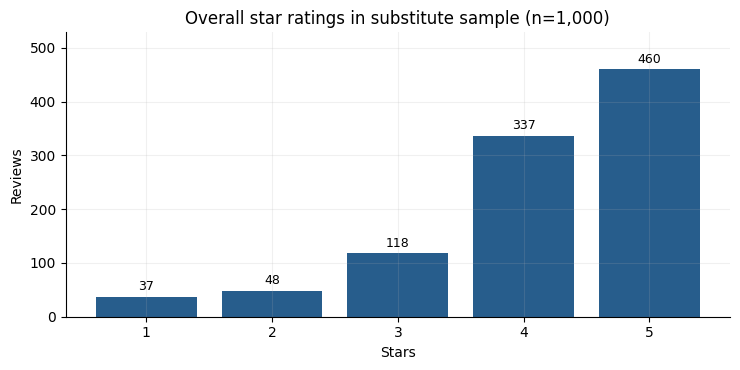

Majority-class accuracy without text: 0.460


In [3]:
counts = data['overall'].value_counts().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(counts.index.astype(str), counts.values, color=BLUE)
ax.set(title=f'Overall star ratings in substitute sample (n={len(data):,})',
       xlabel='Stars', ylabel='Reviews')
for x, y in zip(range(5), counts.values):
    ax.text(x, y + max(counts) * .015, f'{y:,}', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()
print(f'Majority-class accuracy without text: {counts.max() / counts.sum():.3f}')

## Results

### 4. Shared feature, split, and scoring helpers

The vectorizer and optional TF-IDF transform are fit on training text only. The paper uses the term *2/3-gram* for word bigrams and trigrams. Its Table 2 settings are transcribed below.

| Features | Stop words removed | Minimum document frequency | Maximum document frequency |
|---|---:|---:|---:|
| 1 word | Yes | None | None |
| 5 characters | No | 1% | 90% |
| 2 or 3 words | No | 2 reviews | 20% |

In [4]:
FEATURES = {
    '1-word': dict(analyzer='word', ngram_range=(1, 1), stop_words='english'),
    '5-char': dict(analyzer='char', ngram_range=(5, 5), min_df=.01, max_df=.90),
    '2/3-word': dict(analyzer='word', ngram_range=(2, 3), min_df=2, max_df=.20),
}

def get_labeled(frame, target):
    return frame.loc[frame[target].notna(), ['review_text', target]].copy()

def split_target(frame, target, sample_size=None, seed=SEED):
    labeled = get_labeled(frame, target)
    if sample_size is not None and sample_size < len(labeled):
        labeled = labeled.sample(n=sample_size, random_state=seed)
    return train_test_split(labeled['review_text'].to_numpy(),
                            labeled[target].astype(int).to_numpy(),
                            test_size=1/3, random_state=seed)

def feature_matrix(train_text, test_text, feature='1-word', tfidf=True):
    steps = [('counts', CountVectorizer(**FEATURES[feature]))]
    if tfidf:
        steps.append(('tfidf', TfidfTransformer()))
    featurizer = Pipeline(steps)
    return featurizer.fit_transform(train_text), featurizer.transform(test_text)

def to_stars(raw_prediction):
    return np.floor(np.clip(np.asarray(raw_prediction, dtype=float), 1, 5) + .5).clip(1, 5).astype(int)

def polarity(stars):
    stars = np.asarray(stars)
    return np.where(stars < 3, 'negative', np.where(stars > 3, 'positive', 'neutral'))

def scores(y_true, prediction, regression=False):
    predicted_stars = to_stars(prediction) if regression else np.asarray(prediction, dtype=int)
    exact = (np.abs(np.asarray(prediction) - y_true) <= .5).mean() if regression else accuracy_score(y_true, predicted_stars)
    return {'star accuracy': exact,
            'polarity accuracy': accuracy_score(polarity(y_true), polarity(predicted_stars)),
            'balanced star accuracy': balanced_accuracy_score(y_true, predicted_stars),
            'macro F1': f1_score(y_true, predicted_stars, labels=[1, 2, 3, 4, 5], average='macro', zero_division=0)}

def new_svm(balance=True):
    return LinearSVC(C=1, class_weight='balanced' if balance else None,
                     dual=True, max_iter=5000, random_state=SEED)

### 5. Class-balance comparison — Table 1 counterpart

All four methods use the same split and vocabulary. Oversampling and undersampling affect training rows only. The paper's Table 1 reports the following star accuracies on its original corpus; the values computed below refer only to the substitute sample.

| Paper method | Train | Test |
|---|---:|---:|
| No balance | 0.585 | 0.551 |
| Class weight | 0.718 | 0.614 |
| Over-sample | 0.610 | 0.562 |
| Sub-sample | 0.720 | 0.581 |

In [5]:
def resample_rows(matrix, labels, mode, seed=SEED):
    rng = np.random.default_rng(seed)
    classes, class_counts = np.unique(labels, return_counts=True)
    target_count = class_counts.max() if mode == 'over-sample' else class_counts.min()
    indices = np.concatenate([
        rng.choice(np.flatnonzero(labels == cls), size=target_count,
                   replace=(mode == 'over-sample')) for cls in classes
    ])
    rng.shuffle(indices)
    return matrix[indices], labels[indices]

x_train, x_test, y_train, y_test = split_target(data, 'overall')
X_train, X_test = feature_matrix(x_train, x_test, '1-word', tfidf=True)
balance_rows = []
for mode in ['no balance', 'class weight', 'over-sample', 'sub-sample']:
    X_fit, y_fit = (resample_rows(X_train, y_train, mode)
                    if mode in ['over-sample', 'sub-sample'] else (X_train, y_train))
    model = new_svm(balance=(mode == 'class weight'))
    model.fit(X_fit, y_fit)
    balance_rows.append({'method': mode, 'training rows': len(y_fit),
                         'train accuracy': accuracy_score(y_train, model.predict(X_train)),
                         'test accuracy': accuracy_score(y_test, model.predict(X_test))})
balance_results = pd.DataFrame(balance_rows)
display(balance_results.round(3))

,method,training rows,train accuracy,test accuracy
0,no balance,666,1.000,0.554
1,class weight,666,0.998,0.572
2,over-sample,1535,0.920,0.557
3,sub-sample,140,0.571,0.479


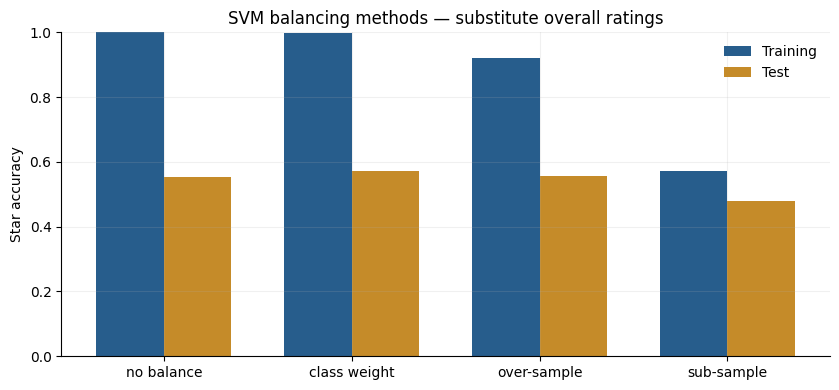

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 4))
positions = np.arange(len(balance_results))
ax.bar(positions - .18, balance_results['train accuracy'], .36, label='Training', color=BLUE)
ax.bar(positions + .18, balance_results['test accuracy'], .36, label='Test', color=GOLD)
ax.set(xticks=positions, xticklabels=balance_results['method'], ylim=(0, 1),
       ylabel='Star accuracy', title='SVM balancing methods — substitute overall ratings')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 6. Model and sample-size comparison — Figures 1–2 counterpart

The original paper compared subsets of roughly 11k–95k reviews. Here the comparison uses 250, 500, 750, and all available **overall-labeled** substitute reviews. This isolates model and sample-size behavior without changing the target across curves.

In [7]:
available = len(get_labeled(data, 'overall'))
sample_sizes = PAPER_SIZES if available >= max(PAPER_SIZES) else sorted(set(min(available, n) for n in [250, 500, 750, available] if min(available, n) >= 60))
model_rows = []
for size in sample_sizes:
    x_train, x_test, y_train, y_test = split_target(data, 'overall', size, seed=SEED)
    X_train, X_test = feature_matrix(x_train, x_test, '1-word', tfidf=True)
    estimators = {'Naive Bayes': (MultinomialNB(), False),
                  'Linear SVM': (new_svm(), False),
                  'Linear regression': (LinearRegression(), True)}
    for model_name, (estimator, is_regression) in estimators.items():
        estimator.fit(X_train, y_train)
        model_rows.append({'n': size, 'model': model_name,
                           **scores(y_test, estimator.predict(X_test), is_regression)})
model_results = pd.DataFrame(model_rows)
display(model_results[['n', 'model', 'star accuracy', 'polarity accuracy']].round(3))

,n,model,star accuracy,polarity accuracy
0,250,Naive Bayes,0.524,0.798
1,250,Linear SVM,0.536,0.786
2,250,Linear regression,0.452,0.786
3,500,Naive Bayes,0.515,0.796
4,500,Linear SVM,0.521,0.802
5,500,Linear regression,0.473,0.832
6,750,Naive Bayes,0.444,0.800
7,750,Linear SVM,0.532,0.812
8,750,Linear regression,0.472,0.792
9,1000,Naive Bayes,0.488,0.787


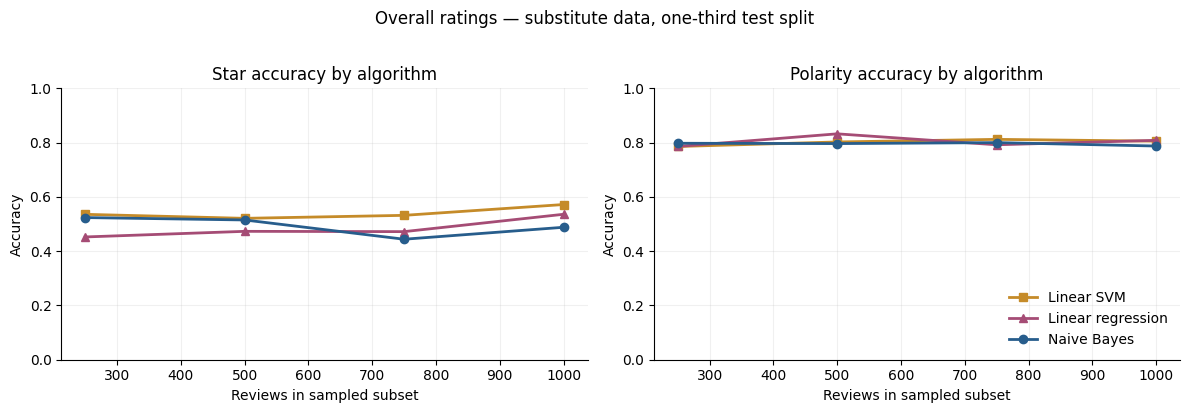

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
style = {'Naive Bayes': (BLUE, 'o'), 'Linear SVM': (GOLD, 's'),
         'Linear regression': (PINK, '^')}
for metric, ax in zip(['star accuracy', 'polarity accuracy'], axes):
    for name, group in model_results.groupby('model'):
        color, marker = style[name]
        ax.plot(group['n'], group[metric], marker=marker, linewidth=2,
                color=color, label=name)
    ax.set(xlabel='Reviews in sampled subset', ylabel='Accuracy',
           title=f'{metric.capitalize()} by algorithm', ylim=(0, 1))
axes[1].legend(frameon=False, loc='lower right')
fig.suptitle('Overall ratings — substitute data, one-third test split', y=1.02)
plt.tight_layout()
plt.show()

### 7. Feature comparison — Figure 3 counterpart

Each target uses all reviews with that target's label. The same split is reused across feature variants for that target. The paper's feature comparison used 45,970 reviews, so the small-sample ranking here need not agree with its reported 2/3-word winner.

In [9]:
feature_rows = []
for target in targets:
    x_train, x_test, y_train, y_test = split_target(data, target)
    for feature in FEATURES:
        for use_tfidf in [False, True]:
            X_train, X_test = feature_matrix(x_train, x_test, feature, use_tfidf)
            estimator = new_svm()
            estimator.fit(X_train, y_train)
            feature_rows.append({'target': target, 'labeled n': len(y_train) + len(y_test),
                                 'features': f'{feature} {"TF-IDF" if use_tfidf else "counts"}',
                                 **scores(y_test, estimator.predict(X_test))})
feature_results = pd.DataFrame(feature_rows)
display(feature_results[['target', 'labeled n', 'features', 'star accuracy',
                         'polarity accuracy']].round(3))

,target,labeled n,features,star accuracy,polarity accuracy
0,overall,1000,1-word counts,0.548,0.805
1,overall,1000,1-word TF-IDF,0.572,0.805
2,overall,1000,5-char counts,0.539,0.793
3,overall,1000,5-char TF-IDF,0.572,0.811
4,overall,1000,2/3-word counts,0.539,0.793
5,overall,1000,2/3-word TF-IDF,0.545,0.790
6,rooms,1000,1-word counts,0.464,0.728
7,rooms,1000,1-word TF-IDF,0.473,0.737
8,rooms,1000,5-char counts,0.497,0.757
9,rooms,1000,5-char TF-IDF,0.530,0.746


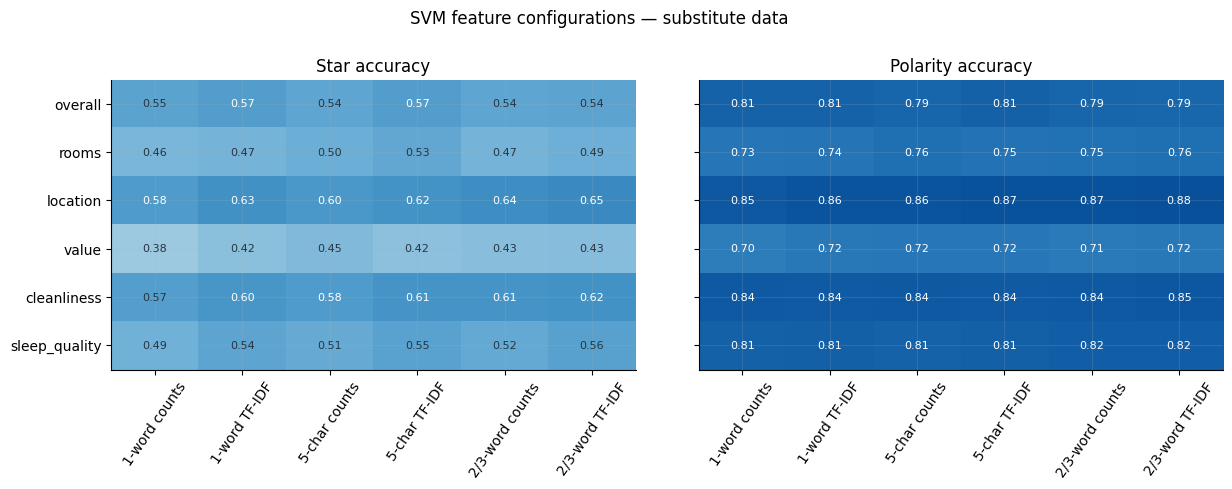

In [10]:
config_order = [f'{feature} {weight}' for feature in FEATURES for weight in ['counts', 'TF-IDF']]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for metric, ax in zip(['star accuracy', 'polarity accuracy'], axes):
    matrix = feature_results.pivot(index='target', columns='features', values=metric).loc[targets, config_order]
    image = ax.imshow(matrix.to_numpy(), vmin=0, vmax=1, cmap='Blues', aspect='auto')
    ax.set(xticks=range(len(config_order)), yticks=range(len(targets)),
           xticklabels=config_order, yticklabels=targets, title=metric.capitalize())
    ax.tick_params(axis='x', labelrotation=55)
    for i in range(len(targets)):
        for j in range(len(config_order)):
            value = matrix.iat[i, j]
            ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                    color='white' if value > .57 else CHARCOAL, fontsize=8)
fig.suptitle('SVM feature configurations — substitute data', y=1.02)
fig.subplots_adjust(bottom=.30, right=.98, wspace=.12)
plt.show()

### 8. Overall versus aspect-specific training — Figure 4 counterpart

For each aspect, both SVMs train on the **same aspect-labeled training reviews** and are tested on the same aspect-labeled test reviews. Their only difference is the training label: overall rating or that aspect's rating. This controls sample size and feature vocabulary.

In [11]:
compare_rows = []
for aspect in aspects:
    labeled = data.loc[data[aspect].notna(), ['review_text', 'overall', aspect]].copy()
    train, test = train_test_split(labeled, test_size=1/3, random_state=SEED)
    X_train, X_test = feature_matrix(train['review_text'], test['review_text'],
                                     '2/3-word', tfidf=False)
    y_test = test[aspect].astype(int).to_numpy()
    for trained_on in ['overall', aspect]:
        model = new_svm()
        model.fit(X_train, train[trained_on].astype(int).to_numpy())
        compare_rows.append({'aspect': aspect, 'trained on': 'aspect' if trained_on == aspect else 'overall',
                             'test n': len(test), **scores(y_test, model.predict(X_test))})
aspect_results = pd.DataFrame(compare_rows)
display(aspect_results[['aspect', 'trained on', 'test n', 'star accuracy',
                        'polarity accuracy']].round(3))

,aspect,trained on,test n,star accuracy,polarity accuracy
0,rooms,overall,334,0.536,0.772
1,rooms,aspect,334,0.473,0.749
2,location,overall,334,0.563,0.847
3,location,aspect,334,0.638,0.871
4,value,overall,334,0.461,0.746
5,value,aspect,334,0.428,0.713
6,cleanliness,overall,334,0.593,0.847
7,cleanliness,aspect,334,0.611,0.841
8,sleep_quality,overall,334,0.542,0.817
9,sleep_quality,aspect,334,0.521,0.823


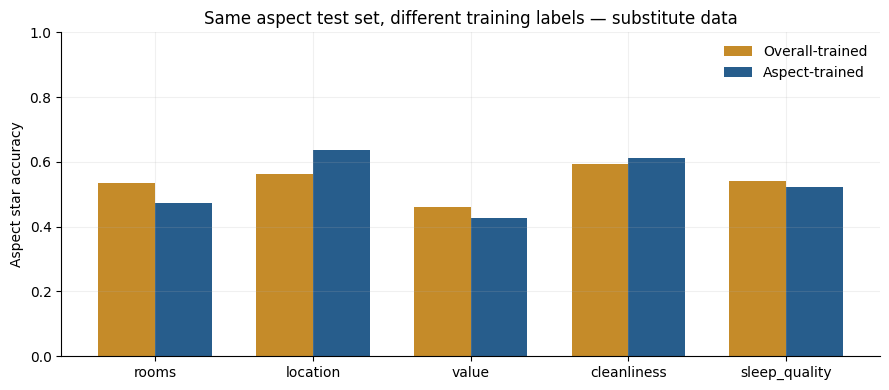

In [12]:
pivot = aspect_results.pivot(index='aspect', columns='trained on', values='star accuracy').loc[aspects]
fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(aspects))
ax.bar(positions - .18, pivot['overall'], .36, label='Overall-trained', color=GOLD)
ax.bar(positions + .18, pivot['aspect'], .36, label='Aspect-trained', color=BLUE)
ax.set(xticks=positions, xticklabels=aspects, ylim=(0, 1), ylabel='Aspect star accuracy',
       title='Same aspect test set, different training labels — substitute data')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 9. Fit the paper-style review analyzer

The paper's final choice was a class-weighted linear SVM with word 2/3-gram counts. The models below use **all** available labeled substitute reviews after the held-out experiments above; their example predictions are illustrative, not test-set performance estimates. An aspect receives a predicted rating even if it is absent from the input text, a limitation the paper discusses.

In [13]:
final_models = {}
for target in targets:
    labeled = get_labeled(data, target)
    model = Pipeline([('counts', CountVectorizer(**FEATURES['2/3-word'])),
                      ('svm', new_svm())])
    model.fit(labeled['review_text'], labeled[target].astype(int))
    final_models[target] = model

def analyze_review(title, body):
    text = f'{title} {body}'.strip()
    if not text:
        raise ValueError('Provide a nonempty review title or body.')
    rows = []
    for target, model in final_models.items():
        star = int(model.predict([text])[0])
        rows.append({'rating target': target, 'predicted stars': star,
                     'predicted polarity': polarity([star])[0]})
    return pd.DataFrame(rows)

display(analyze_review('Convenient stay',
                       'Great location near the station, a quiet clean room, and fair value.'))

,rating target,predicted stars,predicted polarity
0,overall,4,positive
1,rooms,5,positive
2,location,5,positive
3,value,3,neutral
4,cleanliness,5,positive
5,sleep_quality,4,positive


## Takeaways

The cells below calculate the leading method and the aspect-training differences from this notebook's **executed** outputs. Treat them as evidence about the public substitute only. A closer numerical reproduction would need the original Wang et al. corpus, the paper's exact sampled review IDs, and unspecified hyperparameters.

In [14]:
best_balance = balance_results.loc[balance_results['test accuracy'].idxmax()]
best_overall_features = feature_results.loc[
    feature_results.query("target == 'overall'")['star accuracy'].idxmax()]
delta = pivot['aspect'] - pivot['overall']
print(f"Highest SVM test accuracy in the balance comparison: {best_balance['method']} "
      f"({best_balance['test accuracy']:.3f}).")
print(f"Highest overall star accuracy among feature variants: {best_overall_features['features']} "
      f"({best_overall_features['star accuracy']:.3f}).")
print(f"Aspect-trained minus overall-trained star accuracy: median {delta.median():+.3f}; "
      f"higher in {(delta > 0).sum()} of {len(delta)} available aspects.")

Highest SVM test accuracy in the balance comparison: class weight (0.572).
Highest overall star accuracy among feature variants: 1-word TF-IDF (0.572).
Aspect-trained minus overall-trained star accuracy: median -0.021; higher in 2 of 5 available aspects.


### Re-run with another dataset

Set `DATA_PATH` to a local CSV with `title`, `text`, `overall`, and whichever aspect columns are available. Ratings must be integers 1–5; empty and invalid ratings are treated as missing. For a near-original run, include the original aspect columns and sufficient rows to use the paper's four sample sizes. The notebook does not fetch private or changing remote data during execution.

**References:** [Yu's CS229 paper](https://cs229.stanford.edu/proj2016spr/report/032.pdf); [Niimi substitute dataset](https://github.com/jniimi/tripadvisor_dataset); [Li et al. original dataset paper](https://aclanthology.org/D13-1199/).